<a href="https://colab.research.google.com/github/Nandishsk-07/CodeAlpha_DiseasePrediction/blob/main/CodeAlpha_DiseasePrediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**1. Setup**

In [ ]:
!pip install -q xgboost ucimlrepo

In [ ]:
import os, warnings, joblib
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_validate,
                                     cross_val_predict, GridSearchCV)
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix)

try:
    from xgboost import XGBClassifier
    HAS_XGB = True
except ImportError:
    HAS_XGB = False
    print("XGBoost not found - run  !pip install xgboost  to include it.")

SEED = 42
sns.set_style("whitegrid")

In [ ]:
# ---------------- Configuration ----------------
N_SPLITS = 5                 # cross-validation folds
TEST_SIZE = 0.2              # hold-out test share
TARGET_RECALL = 0.90         # recall we want to reach when choosing a decision threshold

# Optional: if you downloaded the CSV files from Kaggle, upload them to Colab (Files panel) and keep these names.
# If the files are not found, the notebook downloads the data automatically.
HEART_CSV = "heart.csv"
DIABETES_CSV = "diabetes.csv"
DIABETES_URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"

**2.Load the three datasets**

In [ ]:
def load_breast_cancer_df():
    bc = load_breast_cancer(as_frame=True)
    X = bc.data.copy()
    y = (bc.target == 0).astype(int)            # scikit-learn: 0 = malignant, 1 = benign -> flip so that 1 = malignant
    return X, y

def load_diabetes_df():
    cols = ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness", "Insulin",
            "BMI", "DiabetesPedigreeFunction", "Age", "Outcome"]
    if os.path.exists(DIABETES_CSV):
        df = pd.read_csv(DIABETES_CSV)
        print("Diabetes: loaded", DIABETES_CSV)
    else:
        df = pd.read_csv(DIABETES_URL, header=None, names=cols)
        print("Diabetes: downloaded from the public URL")
    return df.drop(columns="Outcome"), df["Outcome"].astype(int)

def load_heart_df():
    if os.path.exists(HEART_CSV):
        df = pd.read_csv(HEART_CSV)
        print("Heart: loaded", HEART_CSV)
    else:
        from ucimlrepo import fetch_ucirepo          # UCI "Heart Disease" dataset (id 45)
        ds = fetch_ucirepo(id=45)
        df = pd.concat([ds.data.features, ds.data.targets], axis=1)
        print("Heart: downloaded from the UCI repository")
    df = df.replace("?", np.nan)
    target_col = next(c for c in ["num", "target", "condition", "HeartDisease", "output"] if c in df.columns)
    y = (pd.to_numeric(df[target_col]) > 0).astype(int)           # UCI 'num' is 0-4; anything above 0 = disease
    X = df.drop(columns=target_col).apply(pd.to_numeric, errors="coerce")

    # Safety check: in the real data, patients WITH heart disease reach a LOWER maximum heart rate.
    # Some Kaggle copies have the target flipped, so we verify and fix it.
    hr = next((c for c in X.columns if c.lower().startswith("thalac")), None)
    if hr is not None and X.loc[y == 1, hr].mean() > X.loc[y == 0, hr].mean():
        print("WARNING: target looks inverted in this file (disease group has the higher max heart rate) -> flipping it.")
        y = 1 - y
    return X, y

# --- loaders defined above ---

raw = {
    "Breast Cancer": load_breast_cancer_df(),
    "Pima Diabetes": load_diabetes_df(),
    "Heart Disease": load_heart_df(),
}

CLASS_NAMES = {"Breast Cancer": ["benign", "malignant"],
               "Pima Diabetes": ["non-diabetic", "diabetic"],
               "Heart Disease": ["no disease", "disease"]}
CAT_CANDIDATES = {"Heart Disease": ["cp", "restecg", "slope", "thal"]}   # categorical columns (one-hot encoded)

DATA = {}
for name, (X, y) in raw.items():
    cats = [c for c in CAT_CANDIDATES.get(name, []) if c in X.columns]
    DATA[name] = {"X": X.reset_index(drop=True), "y": y.reset_index(drop=True),
                  "cat_cols": cats, "num_cols": [c for c in X.columns if c not in cats],
                  "classes": CLASS_NAMES[name]}

Diabetes: downloaded from the public URL
Heart: downloaded from the UCI repository


**3 Exploratory Data Analysis**

In [ ]:
summary = pd.DataFrame({
    name: {"Rows": len(d["X"]), "Features": d["X"].shape[1],
           "Positive cases (%)": round(d["y"].mean() * 100, 1),
           "Missing values": int(d["X"].isna().sum().sum()),
           "Duplicate rows": int(pd.concat([d["X"], d["y"].rename("y")], axis=1).duplicated().sum())}
    for name, d in DATA.items()}).T
summary

,Rows,Features,Positive cases (%),Missing values,Duplicate rows
Breast Cancer,569.0,30.0,37.3,0.0,0.0
Pima Diabetes,768.0,8.0,34.9,0.0,0.0
Heart Disease,303.0,13.0,45.9,6.0,0.0


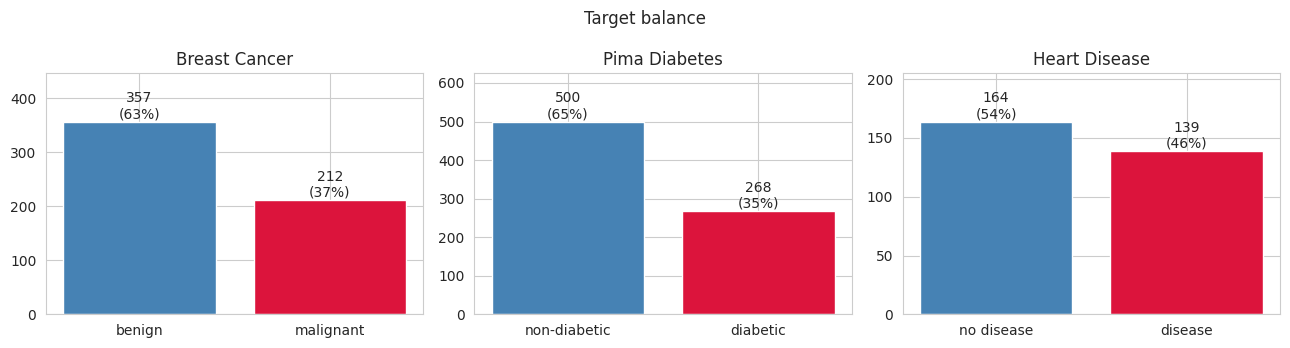

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, (name, d) in zip(axes, DATA.items()):
    counts = d["y"].value_counts().sort_index()
    ax.bar(d["classes"], counts.values, color=["steelblue", "crimson"])
    for i, v in enumerate(counts.values):
        ax.text(i, v, f"{v}\n({v / counts.sum():.0%})", ha="center", va="bottom")
    ax.set_title(name); ax.set_ylim(0, counts.max() * 1.25)
plt.suptitle("Target balance"); plt.tight_layout(); plt.show()

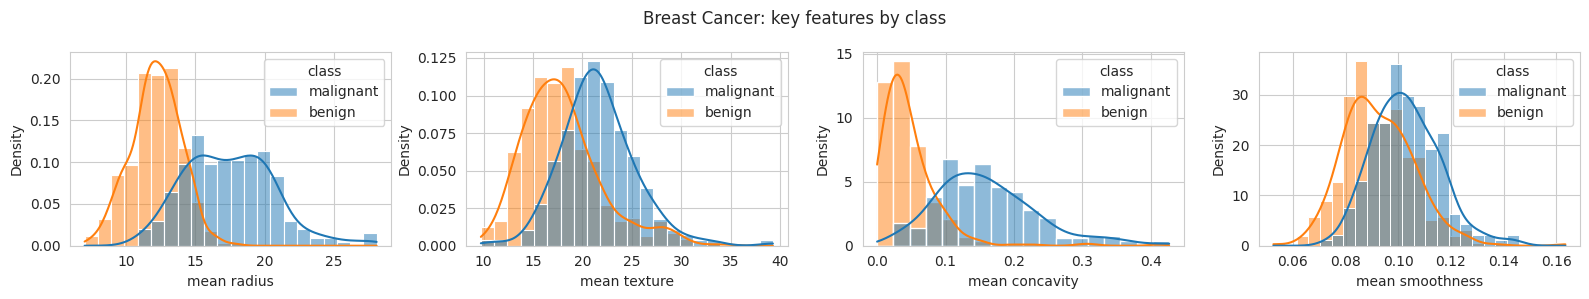

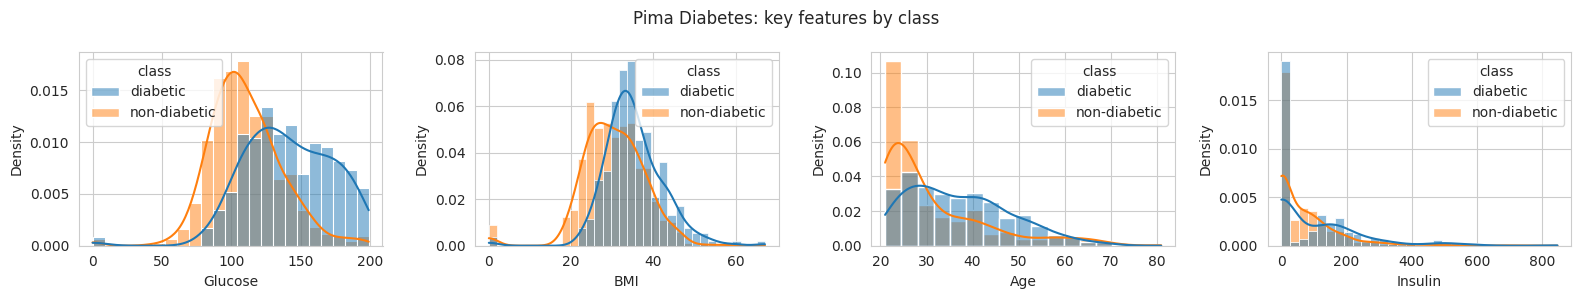

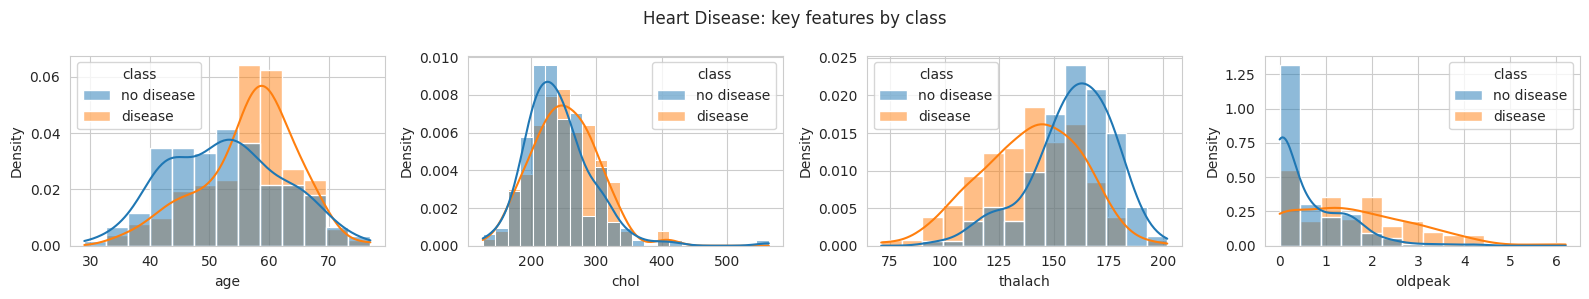

In [ ]:
KEY_FEATURES = {
    "Breast Cancer": ["mean radius", "mean texture", "mean concavity", "mean smoothness"],
    "Pima Diabetes": ["Glucose", "BMI", "Age", "Insulin"],
    "Heart Disease": [c for c in DATA["Heart Disease"]["X"].columns
                      if c.lower().startswith(("age", "thalac", "chol", "oldpeak"))][:4],
}
for name, feats in KEY_FEATURES.items():
    d = DATA[name]
    fig, axes = plt.subplots(1, len(feats), figsize=(4 * len(feats), 3))
    for ax, f in zip(np.ravel(axes), feats):
        tmp = pd.DataFrame({f: d["X"][f], "class": d["y"].map(dict(enumerate(d["classes"])))})
        sns.histplot(data=tmp, x=f, hue="class", kde=True, stat="density", common_norm=False, ax=ax)
    plt.suptitle(f"{name}: key features by class"); plt.tight_layout(); plt.show()

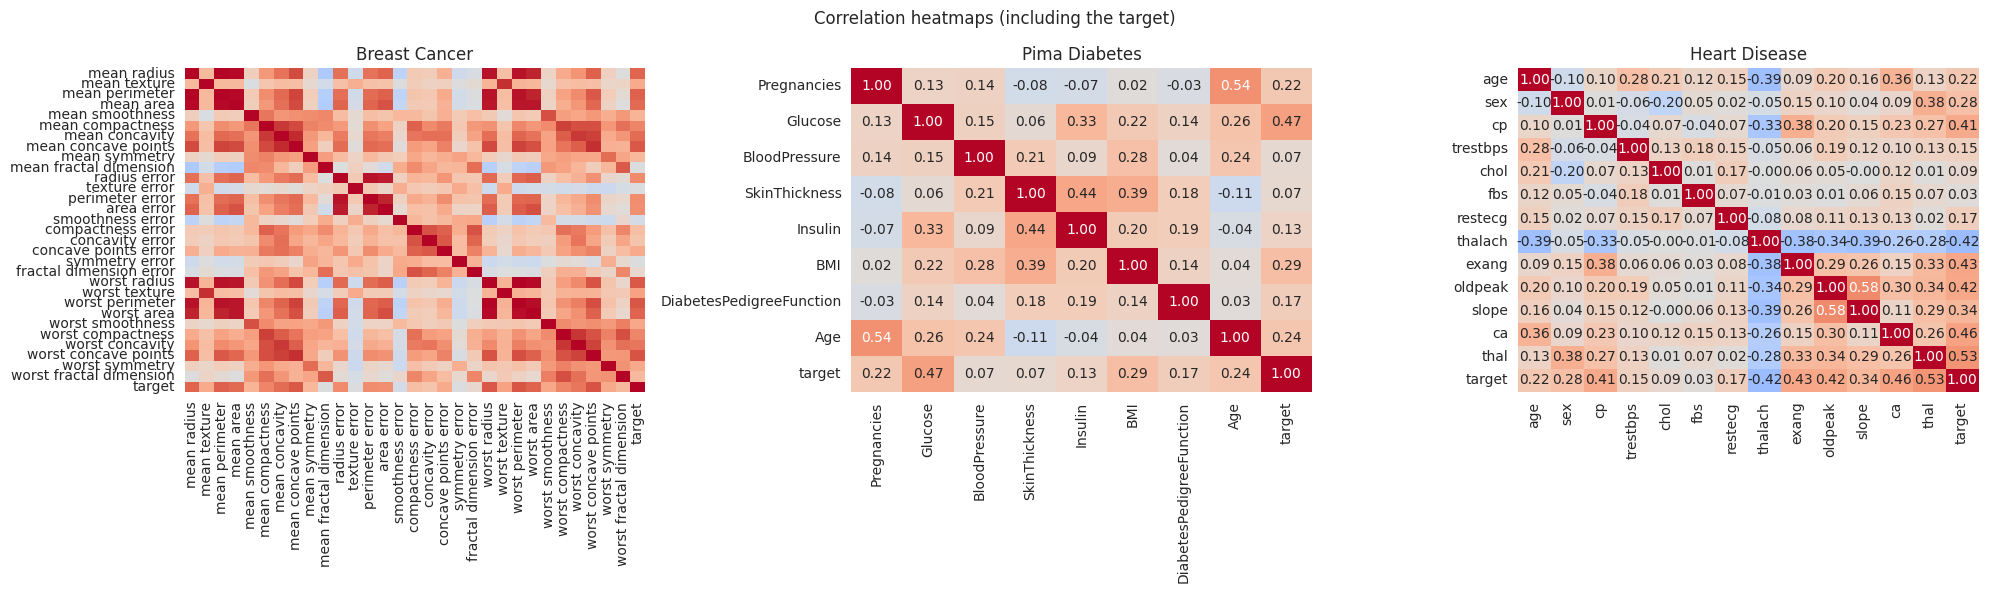

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for ax, (name, d) in zip(axes, DATA.items()):
    corr = pd.concat([d["X"], d["y"].rename("target")], axis=1).corr()
    sns.heatmap(corr, cmap="coolwarm", center=0, annot=len(corr) <= 15, fmt=".2f", ax=ax, cbar=False)
    ax.set_title(name)
plt.suptitle("Correlation heatmaps (including the target)"); plt.tight_layout(); plt.show()

**4. Data Cleaning**

In [ ]:
ZERO_AS_MISSING = {"Pima Diabetes": ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]}

for name, d in DATA.items():
    X, y = d["X"].copy(), d["y"].copy()
    for c in ZERO_AS_MISSING.get(name, []):
        n_zero = int((X[c] == 0).sum())
        X[c] = X[c].replace(0, np.nan)
        print(f"{name}: {c}: {n_zero} impossible zeros -> NaN")
    full = pd.concat([X, y.rename("__y__")], axis=1)
    keep = ~full.duplicated()
    print(f"{name}: removed {int((~keep).sum())} duplicate rows ({len(full)} -> {int(keep.sum())})")
    d["X"], d["y"] = X[keep].reset_index(drop=True), y[keep].reset_index(drop=True)

print()
pd.DataFrame({n: d["X"].isna().sum()[d["X"].isna().sum() > 0] for n, d in DATA.items()}).fillna(0).astype(int)

Breast Cancer: removed 0 duplicate rows (569 -> 569)
Pima Diabetes: Glucose: 5 impossible zeros -> NaN
Pima Diabetes: BloodPressure: 35 impossible zeros -> NaN
Pima Diabetes: SkinThickness: 227 impossible zeros -> NaN
Pima Diabetes: Insulin: 374 impossible zeros -> NaN
Pima Diabetes: BMI: 11 impossible zeros -> NaN
Pima Diabetes: removed 0 duplicate rows (768 -> 768)
Heart Disease: removed 0 duplicate rows (303 -> 303)



,Breast Cancer,Pima Diabetes,Heart Disease
BMI,0,11,0
BloodPressure,0,35,0
Glucose,0,5,0
Insulin,0,374,0
SkinThickness,0,227,0
ca,0,0,4
thal,0,0,2


**5. Train/Test split and the preprocessing pipeline**

In [ ]:
for name, d in DATA.items():
    d["X_train"], d["X_test"], d["y_train"], d["y_test"] = train_test_split(
        d["X"], d["y"], test_size=TEST_SIZE, stratify=d["y"], random_state=SEED)
    print(f"{name:14s} train: {len(d['X_train']):4d} | test: {len(d['X_test']):4d} | "
          f"disease share train/test: {d['y_train'].mean():.1%} / {d['y_test'].mean():.1%}")

Breast Cancer  train:  455 | test:  114 | disease share train/test: 37.4% / 36.8%
Pima Diabetes  train:  614 | test:  154 | disease share train/test: 34.9% / 35.1%
Heart Disease  train:  242 | test:   61 | disease share train/test: 45.9% / 45.9%


In [ ]:
def make_preprocessor(num_cols, cat_cols):
    num = Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())])
    cat = Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                    ("oh", OneHotEncoder(handle_unknown="ignore"))])
    parts = [("num", num, num_cols)]
    if cat_cols:
        parts.append(("cat", cat, cat_cols))
    return ColumnTransformer(parts)

def get_models():
    # class_weight="balanced" gives the (rarer) disease class more weight, which helps recall
    models = {
        "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED),
        "SVM (RBF)": SVC(probability=True, class_weight="balanced", random_state=SEED),
        "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=SEED),
    }
    if HAS_XGB:
        models["XGBoost"] = XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05,
                                          eval_metric="logloss", random_state=SEED)
    return models

def build_pipeline(d, model):
    return Pipeline([("prep", make_preprocessor(d["num_cols"], d["cat_cols"])), ("clf", model)])

def metrics_at(y_true, proba, thr=0.5):
    pred = (np.asarray(proba) >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {"Accuracy": accuracy_score(y_true, pred),
            "Precision": precision_score(y_true, pred, zero_division=0),
            "Recall": recall_score(y_true, pred),
            "Specificity": tn / (tn + fp) if (tn + fp) else np.nan,
            "F1": f1_score(y_true, pred, zero_division=0),
            "ROC-AUC": roc_auc_score(y_true, proba)}

**6. Train and compare the models**

In [ ]:
cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
scoring = {"Accuracy": "accuracy", "Precision": "precision", "Recall": "recall", "F1": "f1", "ROC-AUC": "roc_auc"}

cv_rows, test_rows = [], []
cv_auc = {}                       # (dataset, model) -> mean CV ROC-AUC, used to pick the best model
test_proba, fitted = {}, {}

for ds, d in DATA.items():
    for mname, model in get_models().items():
        pipe = build_pipeline(d, model)
        res = cross_validate(pipe, d["X_train"], d["y_train"], cv=cv, scoring=scoring, n_jobs=-1)
        row = {"Dataset": ds, "Model": mname}
        for k in scoring:
            m, s = res[f"test_{k}"].mean(), res[f"test_{k}"].std()
            row[k] = f"{m:.3f} ± {s:.3f}"
        cv_rows.append(row)
        cv_auc[(ds, mname)] = res["test_ROC-AUC"].mean()

        pipe.fit(d["X_train"], d["y_train"])
        proba = pipe.predict_proba(d["X_test"])[:, 1]
        test_proba[(ds, mname)], fitted[(ds, mname)] = proba, pipe
        test_rows.append({"Dataset": ds, "Model": mname, **metrics_at(d["y_test"], proba)})
    print("done:", ds)

cv_df = pd.DataFrame(cv_rows).set_index(["Dataset", "Model"])
test_df = pd.DataFrame(test_rows).set_index(["Dataset", "Model"]).round(3)

done: Breast Cancer
done: Pima Diabetes
done: Heart Disease


**6a. Cross validation results**

In [ ]:
cv_df

Accuracy      Precision  \
Dataset       Model                                               
Breast Cancer Logistic Regression  0.971 ± 0.018  0.965 ± 0.029   
              SVM (RBF)            0.969 ± 0.011  0.965 ± 0.010   
              Random Forest        0.963 ± 0.013  0.959 ± 0.029   
              XGBoost              0.971 ± 0.011  0.970 ± 0.018   
Pima Diabetes Logistic Regression  0.762 ± 0.011  0.649 ± 0.026   
              SVM (RBF)            0.761 ± 0.034  0.637 ± 0.062   
              Random Forest        0.772 ± 0.028  0.711 ± 0.066   
              XGBoost              0.751 ± 0.019  0.659 ± 0.038   
Heart Disease Logistic Regression  0.847 ± 0.022  0.848 ± 0.055   
              SVM (RBF)            0.797 ± 0.028  0.782 ± 0.057   
              Random Forest        0.818 ± 0.025  0.828 ± 0.032   
              XGBoost              0.781 ± 0.021  0.769 ± 0.041   

                                          Recall             F1        ROC-AUC  
Dataset       Model                                                             
Breast Cancer Logistic Regression  0.959 ± 0.030  0.962 ± 0.024  0.995 ± 0.005  
              SVM (RBF)            0.953 ± 0.035  0.958 ± 0.015  0.995 ± 0.004  
              Random Forest        0.941 ± 0.032  0.949 ± 0.018  0.989 ± 0.007  
              XGBoost              0.953 ± 0.024  0.961 ± 0.015  0.994 ± 0.004  
Pima Diabetes Logistic Regression  0.701 ± 0.039  0.672 ± 0.013  0.844 ± 0.016  
              SVM (RBF)            0.762 ± 0.052  0.690 ± 0.029  0.837 ± 0.031  
              Random Forest        0.593 ± 0.025  0.645 ± 0.033  0.823 ± 0.028  
              XGBoost              0.598 ± 0.052  0.625 ± 0.032  0.811 ± 0.019  
Heart Disease Logistic Regression  0.819 ± 0.051  0.831 ± 0.022  0.907 ± 0.018  
              SVM (RBF)            0.783 ± 0.055  0.780 ± 0.028  0.889 ± 0.024  
              Random Forest        0.765 ± 0.085  0.792 ± 0.040  0.891 ± 0.031  
              XGBoost              0.756 ± 0.081  0.758 ± 0.033  0.858 ± 0.024

**6b. hold out test results**

In [ ]:
test_df

Accuracy  Precision  Recall  Specificity  \
Dataset       Model                                                           
Breast Cancer Logistic Regression     0.974      0.976   0.952        0.986   
              SVM (RBF)               0.982      0.976   0.976        0.986   
              Random Forest           0.965      1.000   0.905        1.000   
              XGBoost                 0.965      1.000   0.905        1.000   
Pima Diabetes Logistic Regression     0.734      0.603   0.704        0.750   
              SVM (RBF)               0.747      0.660   0.574        0.840   
              Random Forest           0.734      0.638   0.556        0.830   
              XGBoost                 0.753      0.660   0.611        0.830   
Heart Disease Logistic Regression     0.869      0.812   0.929        0.818   
              SVM (RBF)               0.902      0.844   0.964        0.848   
              Random Forest           0.902      0.844   0.964        0.848   
              XGBoost                 0.869      0.812   0.929        0.818   

                                      F1  ROC-AUC  
Dataset       Model                                
Breast Cancer Logistic Regression  0.964    0.995  
              SVM (RBF)            0.976    0.995  
              Random Forest        0.950    0.997  
              XGBoost              0.950    0.994  
Pima Diabetes Logistic Regression  0.650    0.813  
              SVM (RBF)            0.614    0.814  
              Random Forest        0.594    0.816  
              XGBoost              0.635    0.827  
Heart Disease Logistic Regression  0.867    0.958  
              SVM (RBF)            0.900    0.956  
              Random Forest        0.900    0.939  
              XGBoost              0.867    0.946

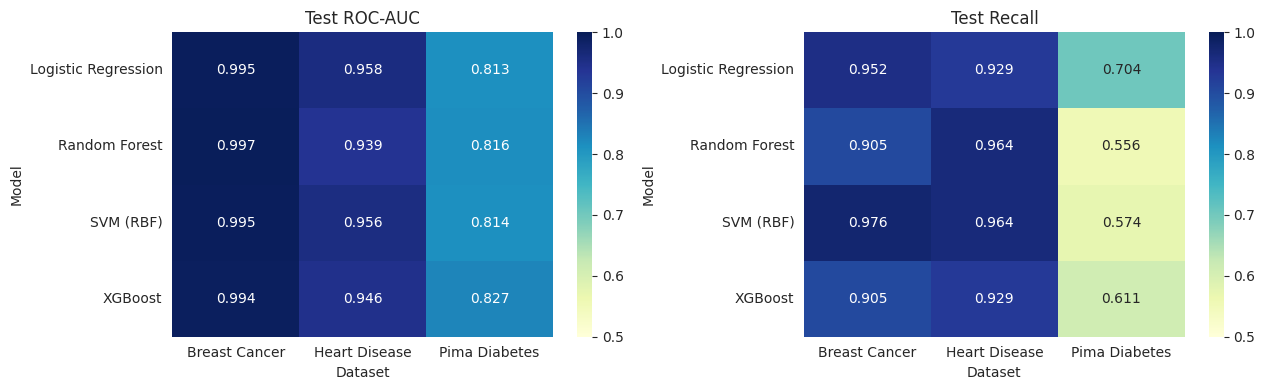

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, metric in zip(axes, ["ROC-AUC", "Recall"]):
    pivot = test_df[metric].unstack(level=0)
    sns.heatmap(pivot, annot=True, fmt=".3f", cmap="YlGnBu", vmin=0.5, vmax=1.0, ax=ax)
    ax.set_title(f"Test {metric}")
plt.tight_layout(); plt.show()

**7. Confusion Matrics**

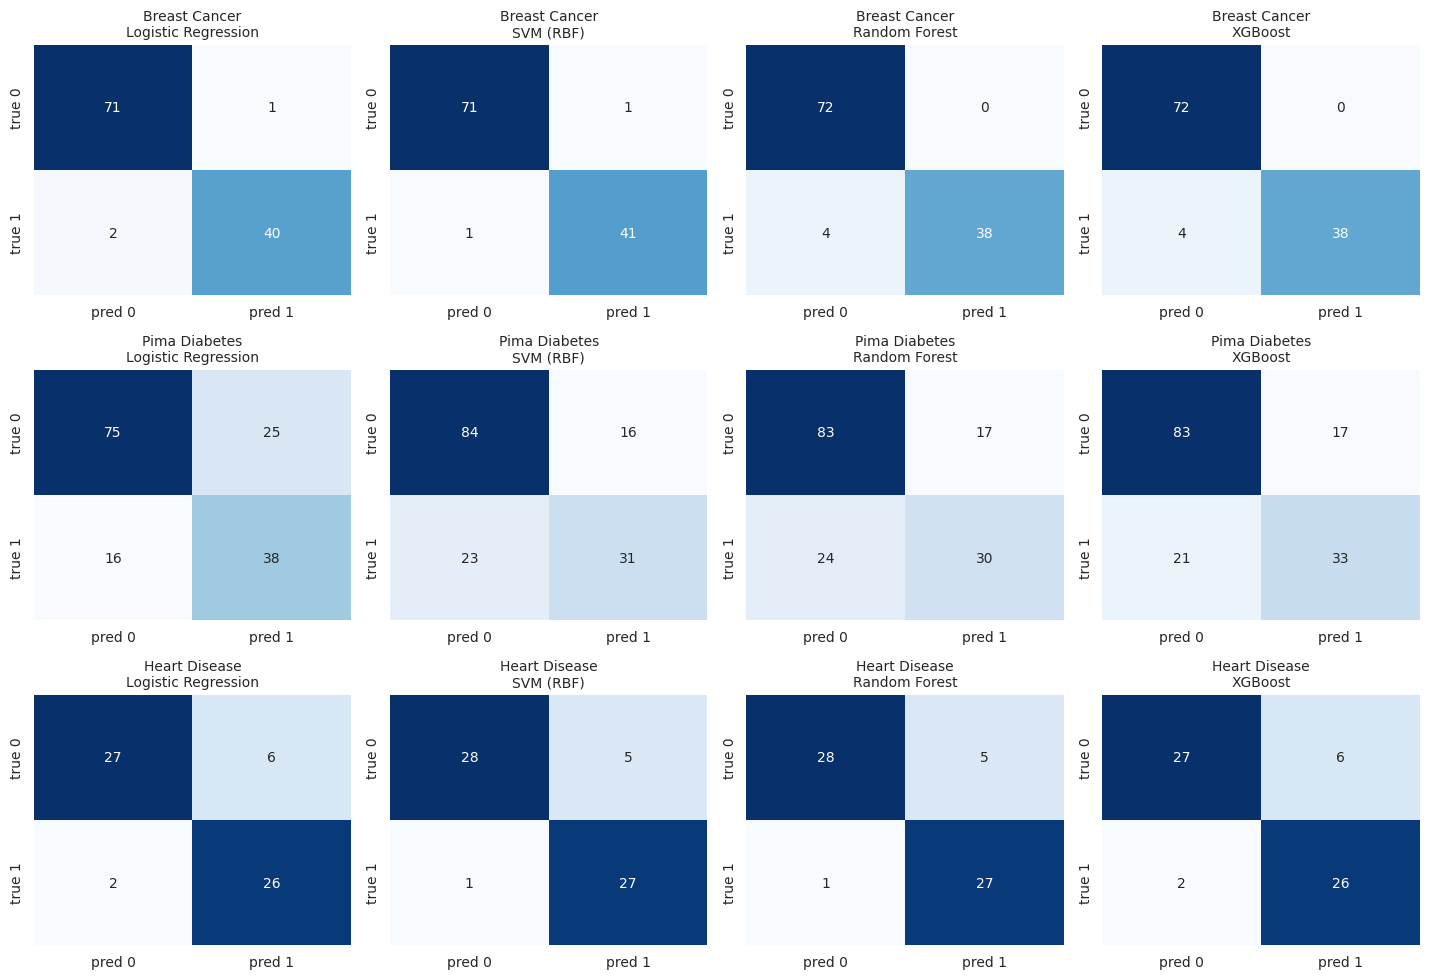

In [ ]:
model_names = list(get_models().keys())
fig, axes = plt.subplots(len(DATA), len(model_names), figsize=(3.6 * len(model_names), 3.3 * len(DATA)))
for i, (ds, d) in enumerate(DATA.items()):
    for j, m in enumerate(model_names):
        pred = (test_proba[(ds, m)] >= 0.5).astype(int)
        cm = confusion_matrix(d["y_test"], pred, labels=[0, 1])
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[i, j],
                    xticklabels=["pred 0", "pred 1"], yticklabels=["true 0", "true 1"])
        axes[i, j].set_title(f"{ds}\n{m}", fontsize=10)
plt.tight_layout(); plt.show()

**8. ROC Curve**

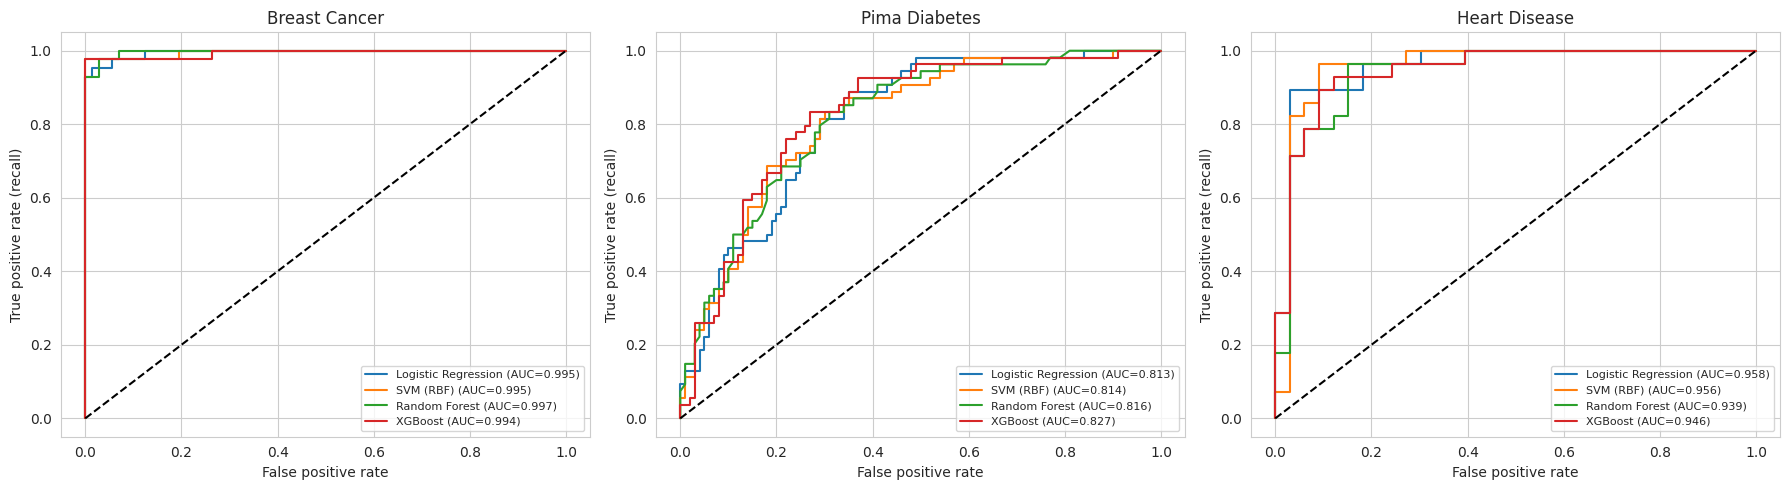

In [ ]:
fig, axes = plt.subplots(1, len(DATA), figsize=(6 * len(DATA), 5))
for ax, (ds, d) in zip(axes, DATA.items()):
    for m in model_names:
        fpr, tpr, _ = roc_curve(d["y_test"], test_proba[(ds, m)])
        ax.plot(fpr, tpr, label=f"{m} (AUC={roc_auc_score(d['y_test'], test_proba[(ds, m)]):.3f})")
    ax.plot([0, 1], [0, 1], "k--"); ax.set_title(ds)
    ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate (recall)"); ax.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

**9. Hyperparameter tunning**

In [ ]:
PARAM_GRIDS = {
    "Logistic Regression": {"clf__C": [0.01, 0.1, 1, 10, 100]},
    "SVM (RBF)": {"clf__C": [0.1, 1, 10, 100], "clf__gamma": ["scale", 0.01, 0.1]},
    "Random Forest": {"clf__n_estimators": [200, 400], "clf__max_depth": [None, 4, 8], "clf__min_samples_leaf": [1, 3, 5]},
    "XGBoost": {"clf__n_estimators": [200, 400], "clf__max_depth": [2, 3, 4], "clf__learning_rate": [0.03, 0.1]},
}

best = {}
tune_rows = []
for ds, d in DATA.items():
    best_name = max(model_names, key=lambda m: cv_auc[(ds, m)])
    gs = GridSearchCV(build_pipeline(d, get_models()[best_name]), PARAM_GRIDS[best_name],
                      cv=cv, scoring="roc_auc", n_jobs=-1, refit=True)
    gs.fit(d["X_train"], d["y_train"])
    proba = gs.best_estimator_.predict_proba(d["X_test"])[:, 1]
    best[ds] = {"model_name": best_name, "estimator": gs.best_estimator_, "test_proba": proba}
    tune_rows.append({
        "Dataset": ds, "Best model": best_name,
        "CV ROC-AUC before": round(cv_auc[(ds, best_name)], 4),
        "CV ROC-AUC after": round(gs.best_score_, 4),
        "Test ROC-AUC before": round(roc_auc_score(d["y_test"], test_proba[(ds, best_name)]), 4),
        "Test ROC-AUC after": round(roc_auc_score(d["y_test"], proba), 4),
        "Best parameters": {k.replace("clf__", ""): v for k, v in gs.best_params_.items()}})
pd.DataFrame(tune_rows).set_index("Dataset")

,Best model,CV ROC-AUC before,CV ROC-AUC after,Test ROC-AUC before,Test ROC-AUC after,Best parameters
Dataset,,,,,,
Breast Cancer,Logistic Regression,0.9954,0.9954,0.9954,0.9954,{'C': 1}
Pima Diabetes,Logistic Regression,0.8444,0.8450,0.8126,0.8104,{'C': 0.1}
Heart Disease,Logistic Regression,0.9069,0.9096,0.9578,0.9610,{'C': 0.1}


**10. Decision-threshold analysis**

Breast Cancer - tuned Logistic Regression | chosen threshold = 0.50 (OOF recall >= 90%)
           Precision  Recall  Specificity     F1
Threshold                                       
0.2            0.888   0.982        0.926  0.933
0.3            0.927   0.976        0.954  0.951
0.4            0.954   0.971        0.972  0.962
0.5            0.964   0.959        0.979  0.962
0.6            0.982   0.953        0.989  0.967
0.7            0.994   0.935        0.996  0.964

Test set:
                 Accuracy  Precision  Recall  Specificity     F1
threshold 0.50     0.974      0.976   0.952        0.986  0.964


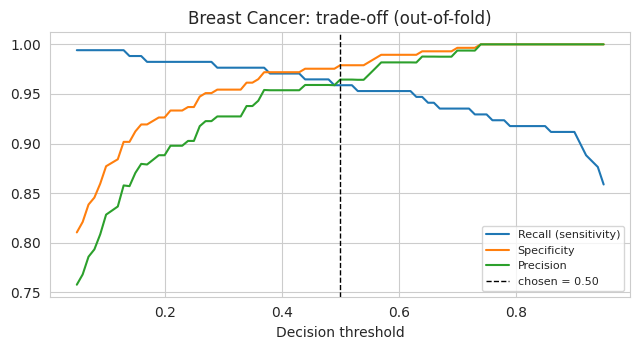

Pima Diabetes - tuned Logistic Regression | chosen threshold = 0.33 (OOF recall >= 90%)
           Precision  Recall  Specificity     F1
Threshold                                       
0.2            0.454   0.986        0.365  0.622
0.3            0.500   0.911        0.512  0.646
0.4            0.564   0.822        0.660  0.669
0.5            0.650   0.720        0.792  0.683
0.6            0.724   0.626        0.872  0.672
0.7            0.767   0.523        0.915  0.622

Test set:
                 Accuracy  Precision  Recall  Specificity     F1
threshold 0.50     0.708      0.571   0.667         0.73  0.615
threshold 0.33     0.701      0.545   0.889         0.60  0.676


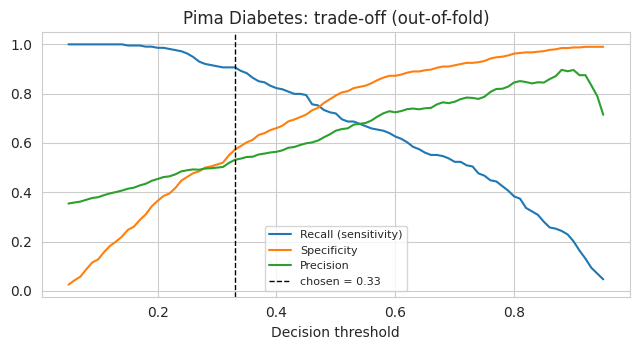

Heart Disease - tuned Logistic Regression | chosen threshold = 0.33 (OOF recall >= 90%)
           Precision  Recall  Specificity     F1
Threshold                                       
0.2            0.598   0.964        0.450  0.738
0.3            0.675   0.937        0.618  0.785
0.4            0.780   0.865        0.794  0.821
0.5            0.848   0.802        0.878  0.824
0.6            0.890   0.730        0.924  0.802
0.7            0.907   0.613        0.947  0.731

Test set:
                 Accuracy  Precision  Recall  Specificity     F1
threshold 0.50     0.869      0.812   0.929        0.818  0.867
threshold 0.33     0.820      0.718   1.000        0.667  0.836


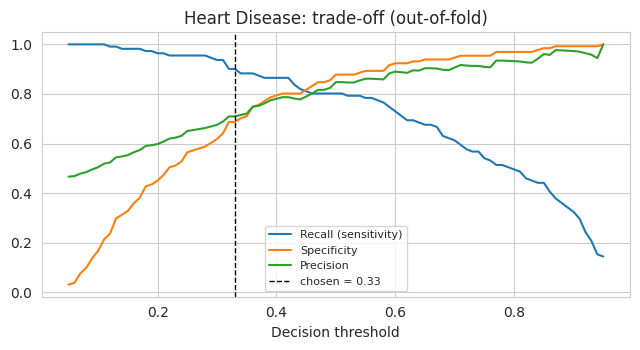

In [ ]:
thresholds = np.round(np.arange(0.05, 0.96, 0.01), 2)
chosen = {}

for ds, d in DATA.items():
    est = best[ds]["estimator"]
    oof = cross_val_predict(clone(est), d["X_train"], d["y_train"], cv=cv, method="predict_proba")[:, 1]
    table = pd.DataFrame([{"Threshold": t, **metrics_at(d["y_train"], oof, t)} for t in thresholds]).set_index("Threshold")
    ok = table[table["Recall"] >= TARGET_RECALL]
    thr = min(0.5, float(ok.index.max())) if len(ok) else 0.5     # only ever lower the threshold below 0.5, never raise it
    chosen[ds] = thr

    print("=" * 70)
    print(f"{ds} - tuned {best[ds]['model_name']} | chosen threshold = {thr:.2f} (OOF recall >= {TARGET_RECALL:.0%})")
    display_rows = table.loc[[0.2, 0.3, 0.4, 0.5, 0.6, 0.7], ["Precision", "Recall", "Specificity", "F1"]].round(3)
    print(display_rows.to_string())

    p_test = best[ds]["test_proba"]
    cmp = pd.DataFrame({"threshold 0.50": metrics_at(d["y_test"], p_test, 0.5),
                        f"threshold {thr:.2f}": metrics_at(d["y_test"], p_test, thr)}).T.round(3)
    print("\nTest set:\n", cmp[["Accuracy", "Precision", "Recall", "Specificity", "F1"]].to_string())

    fig, ax = plt.subplots(figsize=(6.5, 3.6))
    ax.plot(table.index, table["Recall"], label="Recall (sensitivity)")
    ax.plot(table.index, table["Specificity"], label="Specificity")
    ax.plot(table.index, table["Precision"], label="Precision")
    ax.axvline(thr, color="k", ls="--", lw=1, label=f"chosen = {thr:.2f}")
    ax.set_xlabel("Decision threshold"); ax.set_title(f"{ds}: trade-off (out-of-fold)"); ax.legend(fontsize=8)
    plt.tight_layout(); plt.show()

**11.Explainability**

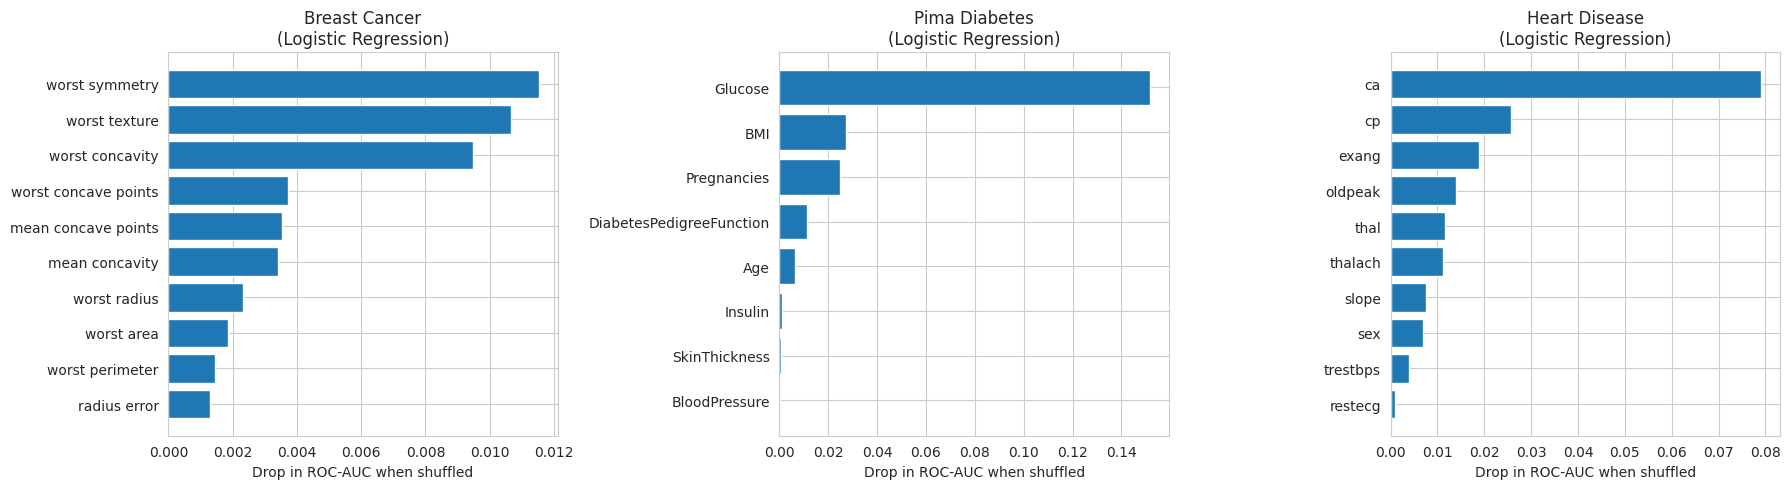

In [ ]:
fig, axes = plt.subplots(1, len(DATA), figsize=(6 * len(DATA), 5))
for ax, (ds, d) in zip(axes, DATA.items()):
    r = permutation_importance(best[ds]["estimator"], d["X_test"], d["y_test"], scoring="roc_auc",
                               n_repeats=20, random_state=SEED, n_jobs=-1)
    imp = pd.Series(r.importances_mean, index=d["X_test"].columns).sort_values().tail(10)
    ax.barh(imp.index, imp.values); ax.set_title(f"{ds}\n({best[ds]['model_name']})")
    ax.set_xlabel("Drop in ROC-AUC when shuffled")
plt.tight_layout(); plt.show()

**12. Predection Demo**

In [ ]:
def predict_patient(dataset, values=None, row=None):
    d, est, thr = DATA[dataset], best[dataset]["estimator"], chosen[dataset]
    if row is None:
        row = pd.DataFrame([{c: (values or {}).get(c, np.nan) for c in d["X"].columns}])
    p = float(est.predict_proba(row)[0, 1])
    verdict = "FLAGGED (screen positive)" if p >= thr else "not flagged"
    print(f"[{dataset}] estimated probability of disease: {p:.1%} -> {verdict} at threshold {thr:.2f}")
    return p

for ds, d in DATA.items():
    i = int(np.random.default_rng(3).integers(len(d["X_test"])))
    print("True label:", d["classes"][int(d["y_test"].iloc[i])])
    predict_patient(ds, row=d["X_test"].iloc[[i]])
    print()

# A "what-if" example for diabetes with only some values provided
predict_patient("Pima Diabetes", {"Glucose": 165, "BMI": 36.5, "Age": 52, "Pregnancies": 4})

True label: benign
[Breast Cancer] estimated probability of disease: 12.1% -> not flagged at threshold 0.50

True label: diabetic
[Pima Diabetes] estimated probability of disease: 46.1% -> FLAGGED (screen positive) at threshold 0.33

True label: no disease
[Heart Disease] estimated probability of disease: 19.1% -> not flagged at threshold 0.33

[Pima Diabetes] estimated probability of disease: 86.2% -> FLAGGED (screen positive) at threshold 0.33


0.8622234884264778

In [ ]:
joblib.dump({ds: {"model": best[ds]["estimator"], "threshold": chosen[ds], "columns": list(DATA[ds]["X"].columns),
                  "classes": DATA[ds]["classes"]} for ds in DATA}, "disease_prediction_models.joblib")
print("Saved disease_prediction_models.joblib")

Saved disease_prediction_models.joblib
